# Temă LP3 — Preprocesarea datelor (Titanic)

**Timp de lucru: maximum 15 minute** · lucru individual

Aplicați tehnicile din LP3 pe un set de date nou: **Titanic** — informații despre pasagerii navei (vârstă, sex, preț bilet, port de îmbarcare, punte) și dacă au supraviețuit (`survived`).

| Sarcina | Tema | Timp |
| --- | --- | --- |
| 1 | Valori lipsă: diagnostic și eliminare pe bază de prag | ~3 min |
| 2 | Imputarea valorilor lipsă | ~3 min |
| 3 | Asimetrie și transformare logaritmică | ~3 min |
| 4 | Outlieri (regula IQR) | ~3 min |
| 5 | Encoding și scalare | ~3 min |

> 💡 Completați celulele marcate `# TODO`. Nu e nevoie de cod perfect — contează să înțelegeți ce face fiecare pas.

### Pregătire — rulați celula (nu necesită modificări)

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

titanic = sns.load_dataset('titanic')
df = titanic[['survived', 'pclass', 'sex', 'age', 'fare', 'embarked', 'deck']].copy()
df.head(15)

,survived,pclass,sex,age,fare,embarked,deck
0,0,3,male,22.0,7.2500,S,NaN
1,1,1,female,38.0,71.2833,C,C
2,1,3,female,26.0,7.9250,S,NaN
3,1,1,female,35.0,53.1000,S,C
4,0,3,male,35.0,8.0500,S,NaN
5,0,3,male,NaN,8.4583,Q,NaN
6,0,1,male,54.0,51.8625,S,E
7,0,3,male,2.0,21.0750,S,NaN
8,1,3,female,27.0,11.1333,S,NaN
9,1,2,female,14.0,30.0708,C,NaN


## Sarcina 1 — Valori lipsă (~3 min)

**1.1** Calculați procentul de valori lipsă pentru fiecare coloană, sortat descrescător.

**1.2** Eliminați coloanele cu **mai mult de 50%** valori lipsă. Care coloană dispare?

In [16]:
# 1.1 — procentul de valori lipsă pe coloană
print((df.isnull().mean() * 100).round(2).sort_values(ascending=False))

# 1.2 — eliminați coloanele cu > 50% valori lipsă
def drop_columns_with_high_nulls(df, threshold_percentage):
    threshold = len(df) * (threshold_percentage / 100)
    dropped_columns = df.columns[df.isnull().sum() > threshold]
    df_cleaned = df.drop(columns=dropped_columns)
    return df_cleaned, dropped_columns

df, dropped = drop_columns_with_high_nulls(df, 50)
print("Coloane eliminate:", list(dropped))

deck        77.22
age         19.87
embarked     0.22
sex          0.00
pclass       0.00
survived     0.00
fare         0.00
dtype: float64
Coloane eliminate: ['deck']


## Sarcina 2 — Imputarea valorilor lipsă (~3 min)

**2.1** Imputați `age` cu **mediana** și `embarked` cu **valoarea cea mai frecventă** (modul).

**2.2** Verificați că nu mai există valori lipsă și comparați deviația standard a lui `age` înainte și după imputare. *(salvați înainte de imputare: `age_inainte = df['age'].copy()`)*

In [ ]:
# 2.1 — imputare age (mediană) și embarked (mod)
age_inainte = df['age'].copy()
df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df.head(15)

# 2.2 — verificare + comparație deviație standard
print("Valori lipsă rămase:", df.isna().sum().sum())
print("Std age înainte:", round(age_inainte.std(), 2))
print("Std age după:   ", round(df['age'].std(), 2))

Valori lipsă rămase: 0
Std age înainte: 14.53
Std age după:    13.02


## Sarcina 3 — Asimetrie și transformare logaritmică (~3 min)

**3.1** Calculați skewness-ul variabilei `fare`.

**3.2** Creați coloana `log_fare = np.log1p(fare)` și calculați skewness-ul ei. A ajutat transformarea?

**3.3** Desenați cele două histograme una lângă alta.

Skewness fare: 4.79
Skewness log_fare: 0.39


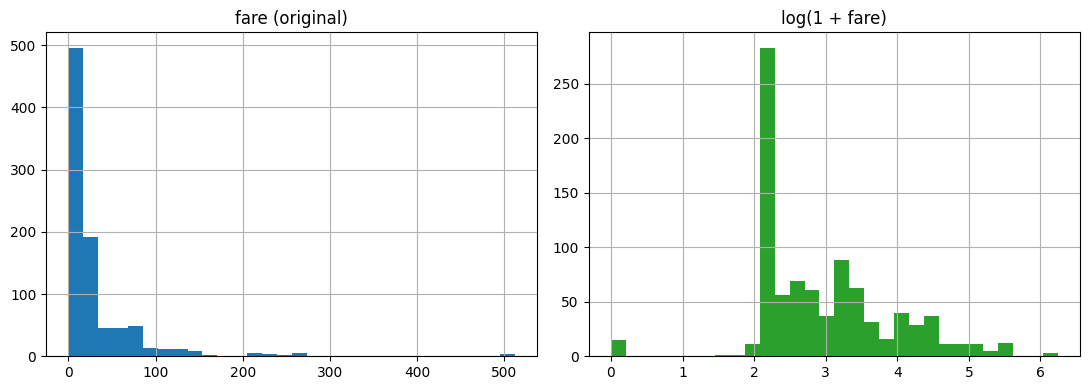

In [21]:
# 3.1 — skewness fare
print("Skewness fare:", round(df['fare'].skew(), 2))

# 3.2 — coloana log_fare + skewness
df['log_fare'] = np.log1p(df['fare'])
print("Skewness log_fare:", round(df['log_fare'].skew(), 2))

# 3.3 — două histograme
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df['fare'].hist(ax=axes[0], bins=30); axes[0].set_title('fare (original)')
df['log_fare'].hist(ax=axes[1], bins=30, color='tab:green'); axes[1].set_title('log(1 + fare)')
plt.tight_layout(); plt.show()

## Sarcina 4 — Outlieri cu regula IQR (~3 min)

**4.1** Calculați limitele `[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]` pentru `fare` și numărați outlierii.

**4.2** Limitați (clip) valorile extreme într-o coloană nouă, `fare_capped`, și afișați maximul înainte și după.

In [22]:
# 4.1 — limite IQR + număr de outlieri
def limite_iqr(serie, k=1.5):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

jos, sus = limite_iqr(df['fare'])
n_out = ((df['fare'] < jos) | (df['fare'] > sus)).sum()
print("Limite:", round(jos, 2), "-", round(sus, 2))
print("Nr. outlieri:", n_out)

# 4.2 — fare_capped (clip) + maxim înainte/după
df['fare_capped'] = df['fare'].clip(lower=jos, upper=sus)
print("Maxim înainte :", df['fare'].max())
print("Maxim după    :", df['fare_capped'].max())

Limite: -26.72 - 65.63
Nr. outlieri: 116
Maxim înainte : 512.3292
Maxim după    : 65.6344


## Sarcina 5 — Encoding și scalare (~3 min)

**5.1** Aplicați One-Hot Encoding pe `sex` și `embarked` (cu `drop_first=True`, `dtype=int`).

**5.2** Standardizați `age` și `fare_capped` cu `StandardScaler`. Verificați că media ≈ 0 și deviația standard ≈ 1.

In [23]:
# 5.1 — One-Hot Encoding pentru sex și embarked
df = pd.get_dummies(df, columns=['sex', 'embarked'], drop_first=True, dtype=int)
print(df.head())

# 5.2 — StandardScaler pentru age și fare_capped + verificare medie/std
cols = ['age', 'fare_capped']
df[cols] = StandardScaler().fit_transform(df[cols])

print(df[cols].agg(['mean', 'std']).round(3))

   survived  pclass   age     fare  log_fare  fare_capped  sex_male  \
0         0       3  22.0   7.2500  2.110213       7.2500         1   
1         1       1  38.0  71.2833  4.280593      65.6344         0   
2         1       3  26.0   7.9250  2.188856       7.9250         0   
3         1       1  35.0  53.1000  3.990834      53.1000         0   
4         0       3  35.0   8.0500  2.202765       8.0500         1   

   embarked_Q  embarked_S  
0           0           1  
1           0           0  
2           0           1  
3           0           1  
4           0           1  
        age  fare_capped
mean  0.000        0.000
std   1.001        1.001


## Întrebare de reflecție (1–2 propoziții)

*De ce am imputat `age`, dar am eliminat `deck`?*

*Răspunsul tău:*

 deck avea ~77% valori lipsă —> prea puține date reale ca să o putem folosi drept sursa valida de informatii. 
 age avea doar ~20% lipsă, deci restul de 80% valori reale permit o imputare rezonabilă (cu mediana), fără să pierdem informatii importante.